In [1]:
import os
import pandas as pd

# Define paths
DATA_DIR = "../data"
IMAGES_DIR = os.path.join(DATA_DIR, "Images")
CAPTIONS_FILE = os.path.join(DATA_DIR, "captions.txt")

# 1. Verify image count
image_files = [f for f in os.listdir(IMAGES_DIR) if f.endswith(".jpg")]
print(f"Total images found: {len(image_files)}")

# 2. Inspect captions
df = pd.read_csv(CAPTIONS_FILE)
print(f"Total caption rows: {len(df)}")
print(f"Unique images in captions file: {df['image'].nunique()}")

# Display the first 5 rows
df.head()

Total images found: 8091
Total caption rows: 40455
Unique images in captions file: 8091


,image,caption
0,1000268201_693b08cb0e.jpg,A child in a pink dress is climbing up a set o...
1,1000268201_693b08cb0e.jpg,A girl going into a wooden building .
2,1000268201_693b08cb0e.jpg,A little girl climbing into a wooden playhouse .
3,1000268201_693b08cb0e.jpg,A little girl climbing the stairs to her playh...
4,1000268201_693b08cb0e.jpg,A little girl in a pink dress going into a woo...


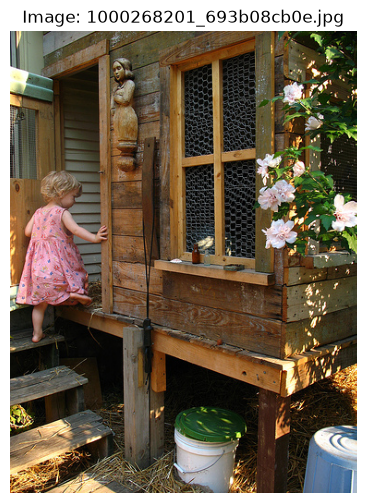

Captions:
1. A child in a pink dress is climbing up a set of stairs in an entry way .
2. A girl going into a wooden building .
3. A little girl climbing into a wooden playhouse .
4. A little girl climbing the stairs to her playhouse .
5. A little girl in a pink dress going into a wooden cabin .


In [3]:
import matplotlib.pyplot as plt
from PIL import Image

# Pick the first image name from the dataset
sample_image_name = df['image'].iloc[0]
sample_image_path = os.path.join(IMAGES_DIR, sample_image_name)

# Fetch all 5 captions belonging to this image
sample_captions = df[df['image'] == sample_image_name]['caption'].tolist()

# Display the image
img = Image.open(sample_image_path)
plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis("off")
plt.title(f"Image: {sample_image_name}")
plt.show()

# Print the 5 captions
print("Captions:")
for i, cap in enumerate(sample_captions, 1):
    print(f"{i}. {cap}")

In [4]:
import random

# Get a sorted, unique list of all image names
unique_images = sorted(df["image"].unique().tolist())

# Fix the random seed so your split is identical every time you run it
random.seed(42)
random.shuffle(unique_images)

# Slice into standard splits
train_images = unique_images[:6000]
val_images = unique_images[6000:7000]
test_images = unique_images[7000:]

print(f"Training set:   {len(train_images)} images")
print(f"Validation set: {len(val_images)} images")
print(f"Testing set:    {len(test_images)} images")

# Function to save image list to a text file
def save_split(filename, image_list):
    filepath = os.path.join(DATA_DIR, filename)
    with open(filepath, "w") as f:
        for item in image_list:
            f.write(f"{item}\n")
    print(f"Saved {filepath}")

# Save all three split files into the data folder
save_split("Flickr_8k.trainImages.txt", train_images)
save_split("Flickr_8k.devImages.txt", val_images)
save_split("Flickr_8k.testImages.txt", test_images)

Training set:   6000 images
Validation set: 1000 images
Testing set:    1091 images
Saved ../data/Flickr_8k.trainImages.txt
Saved ../data/Flickr_8k.devImages.txt
Saved ../data/Flickr_8k.testImages.txt


In [5]:
# Verify zero leakage across splits
train_set = set(train_images)
val_set = set(val_images)
test_set = set(test_images)

assert len(train_set.intersection(val_set)) == 0, "Leakage detected between train and val!"
assert len(train_set.intersection(test_set)) == 0, "Leakage detected between train and test!"
assert len(val_set.intersection(test_set)) == 0, "Leakage detected between val and test!"

print("Sanity check passed: No data leakage across splits!")


Sanity check passed: No data leakage across splits!
